# Feature Engineering & Data Preprocessing

**Name:** Sakshi Kailas Shewale

**PRN:** 202401040126

**Roll No.:** 31

**Course:** Artificial Intelligence and Machine Learning (2304322T)

**Assignment No:** 2 


**Dataset:** *Students Performance in Exams* (Kaggle – `spscientist/students-performance-in-exams`)

**SDG Goal:**  **SDG 4 – Quality Education** (understanding which factors affect student learning outcomes)

**Dataset columns (8):** gender, race/ethnicity, parental level of education, lunch, test preparation course, math score, reading score, writing score  (1000 students)

---
### Steps for performing the Feature Engineering
1. Dataset loading & display
2. Data preprocessing (missing values)
3. Numerical data visualization
4. Categorical data visualization
5. Categorical encoding
6. Feature scaling
7. Feature engineering
8. Final preprocessed dataset


In [ ]:
# ---------- Setup: import all libraries ----------
%pip install -q category_encoders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import (LabelEncoder, OrdinalEncoder, StandardScaler,
                                   MinMaxScaler, RobustScaler, Normalizer, PowerTransformer)
from sklearn.decomposition import PCA
import category_encoders as ce

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')          # clean look for all graphs
pd.set_option('display.max_columns', None)
print('All libraries imported ✅')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 863.5 kB/s eta 0:00:00
All libraries imported ✅


## 1️⃣ Dataset Creation & Display
We load the Kaggle dataset. (Loader tries: Kaggle download → manual upload → backup data.)

In [ ]:
# ---------- Load dataset ----------
def make_backup_data(n=1000, seed=0):
    # Backup dataset with the SAME columns as the Kaggle file (used only if download/upload fails)
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({
        'gender': rng.choice(['female', 'male'], n),
        'race/ethnicity': rng.choice(['group A','group B','group C','group D','group E'], n, p=[.09,.19,.32,.26,.14]),
        'parental level of education': rng.choice(["some high school","high school","some college",
                                                  "associate's degree","bachelor's degree","master's degree"], n,
                                                 p=[.18,.20,.23,.22,.12,.05]),
        'lunch': rng.choice(['standard','free/reduced'], n, p=[.65,.35]),
        'test preparation course': rng.choice(['none','completed'], n, p=[.64,.36]),
    })
    base = rng.normal(66, 14, n) + (d['lunch']=='standard')*7 + (d['test preparation course']=='completed')*5
    d['math score']    = np.clip(base + rng.normal(0, 6, n), 0, 100).round().astype(int)
    d['reading score'] = np.clip(base + 3 + rng.normal(0, 6, n), 17, 100).round().astype(int)
    d['writing score'] = np.clip(base + 2 + rng.normal(0, 6, n), 10, 100).round().astype(int)
    return d

def load_data():
    # 1) try direct download from Kaggle (public dataset)
    try:
        import kagglehub, os
        p = kagglehub.dataset_download('spscientist/students-performance-in-exams')
        csv = [os.path.join(p, f) for f in os.listdir(p) if f.endswith('.csv')][0]
        print('Loaded from Kaggle ✅'); return pd.read_csv(csv)
    except Exception as e:
        print('Kaggle auto-download not available:', type(e).__name__)
    # 2) try manual upload (Colab)
    try:
        from google.colab import files
        print('👉 Upload StudentsPerformance.csv (or press Cancel to use backup data)')
        up = files.upload()
        if up:
            print('Loaded from uploaded file ✅'); return pd.read_csv(list(up.keys())[0])
    except Exception as e:
        pass
    # 3) backup
    print('Using backup dataset (same columns as Kaggle) ✅'); return make_backup_data()

df = load_data()

100%|██████████| 8.70k/8.70k [00:00<00:00, 10.5MB/s]

Extracting files...
Loaded from Kaggle ✅


In [ ]:
# ---------- Rename columns to short names (easier to type and explain) ----------
df = df.rename(columns={'race/ethnicity':'race', 'parental level of education':'parent_edu',
                        'test preparation course':'test_prep',
                        'math score':'math', 'reading score':'reading', 'writing score':'writing'})

print('First 5 rows  (head):');  display(df.head())
print('Last 5 rows   (tail):');  display(df.tail())
print('Shape (rows, columns):', df.shape)

First 5 rows  (head):


,gender,race,parent_edu,lunch,test_prep,math,reading,writing
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Last 5 rows   (tail):


,gender,race,parent_edu,lunch,test_prep,math,reading,writing
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


Shape (rows, columns): (1000, 8)


In [ ]:
print('--- info(): column names, data types, non-null counts ---')
df.info()
print('\n--- describe(): statistics of numerical columns ---')
display(df.describe())

--- info(): column names, data types, non-null counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   gender      1000 non-null   object
 1   race        1000 non-null   object
 2   parent_edu  1000 non-null   object
 3   lunch       1000 non-null   object
 4   test_prep   1000 non-null   object
 5   math        1000 non-null   int64 
 6   reading     1000 non-null   int64 
 7   writing     1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

--- describe(): statistics of numerical columns ---


,math,reading,writing
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [ ]:
# ---------- Identify numerical and categorical features ----------
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()
print('Numerical features  :', num_cols)
print('Categorical features:', cat_cols)

Numerical features  : ['math', 'reading', 'writing']
Categorical features: ['gender', 'race', 'parent_edu', 'lunch', 'test_prep']


**Explanation**
- `head()` / `tail()` show the first / last rows, `shape` gives (1000 rows, 8 columns), `info()` gives data types and non-null counts, `describe()` gives mean, std, min, quartiles, max.
- **Numerical features:** `math`, `reading`, `writing` (scores out of 100).
- **Categorical features:** `gender`, `race`, `parent_edu`, `lunch`, `test_prep`.

## 2️⃣ Data Preprocessing – Missing Values
The original Kaggle dataset is already clean (no missing values). To **practice** missing value handling, we deliberately make **5% of values missing at random** in four columns (fixed `seed`, so the result is the same every time).

In [ ]:
# ---------- Deliberately create missing values (for practice) ----------
rng = np.random.default_rng(42)
for col in ['math', 'reading', 'writing', 'parent_edu']:
    idx = rng.choice(df.index, size=int(0.05 * len(df)), replace=False)   # pick 5% random rows
    df.loc[idx, col] = np.nan

print('Number of missing values in each column:')
missing = pd.DataFrame({'missing_count': df.isnull().sum(),
                        'missing_percent': (df.isnull().mean() * 100).round(2)})
display(missing)

Number of missing values in each column:


,missing_count,missing_percent
gender,0,0.0
race,0,0.0
parent_edu,50,5.0
lunch,0,0.0
test_prep,0,0.0
math,50,5.0
reading,50,5.0
writing,50,5.0


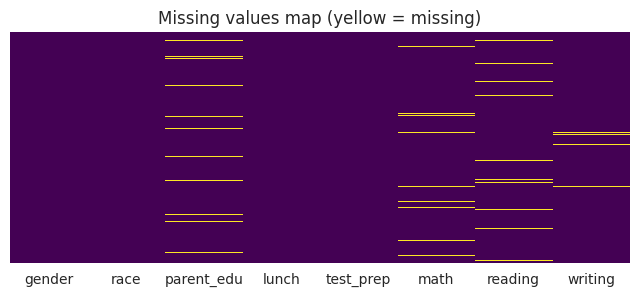

In [ ]:
# Visual check of missing values
plt.figure(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing values map (yellow = missing)')
plt.show()

**Insight:** The yellow lines show missing cells in `math`, `reading`, `writing` and `parent_edu` (about 50 each). Other columns are complete.

In [ ]:
# ---------- Handle missing values (4 different techniques) ----------
df_clean = df.copy()

# 1) MEAN imputation -> 'math' (scores are roughly bell shaped, so mean is a fair centre)
df_clean['math'] = df_clean['math'].fillna(df_clean['math'].mean())

# 2) MEDIAN imputation -> 'reading' (median is not affected by extreme/low scores = outliers)
df_clean['reading'] = df_clean['reading'].fillna(df_clean['reading'].median())

# 3) RANDOM SAMPLE imputation -> 'writing' (fills with random real values, keeps the original distribution/spread)
missing_idx = df_clean[df_clean['writing'].isnull()].index
random_values = df_clean['writing'].dropna().sample(len(missing_idx), replace=True, random_state=1).values
df_clean.loc[missing_idx, 'writing'] = random_values

# 4) MODE imputation -> 'parent_edu' (categorical column, so we use the most frequent category)
df_clean['parent_edu'] = df_clean['parent_edu'].fillna(df_clean['parent_edu'].mode()[0])

print('Missing values AFTER handling:')
print(df_clean.isnull().sum())

Missing values AFTER handling:
gender        0
race          0
parent_edu    0
lunch         0
test_prep     0
math          0
reading       0
writing       0
dtype: int64


### Why each technique?
| Column | Technique | Reason |
|---|---|---|
| `math` | **Mean** | Distribution is almost symmetric, so mean represents the centre well. |
| `reading` | **Median** | A few very low scores (outliers) pull the mean down; median is robust to outliers. |
| `writing` | **Random sample** | Picks random existing values, so the shape/variance of the column is preserved (mean/median would make the spread smaller). |
| `parent_edu` | **Mode** | Categorical data has no mean/median, so we use the most frequent category. |

*(Note: mean/median can't be used for text columns; mode can be used for both.)*

## 3️⃣ Data Visualization – Numerical Data

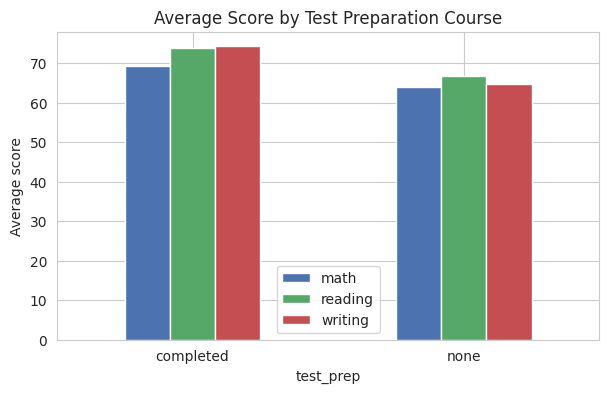

In [ ]:
# ---------- Bar chart: average score per subject, split by test preparation ----------
avg = df_clean.groupby('test_prep')[['math','reading','writing']].mean()
avg.plot(kind='bar', figsize=(7,4), rot=0, color=['#4c72b0','#55a868','#c44e52'])
plt.title('Average Score by Test Preparation Course')
plt.ylabel('Average score')
plt.show()

**Bar chart insight:** Students who **completed** the test-prep course have a higher average in all three subjects, so test preparation helps performance (supports SDG 4 – providing learning support).

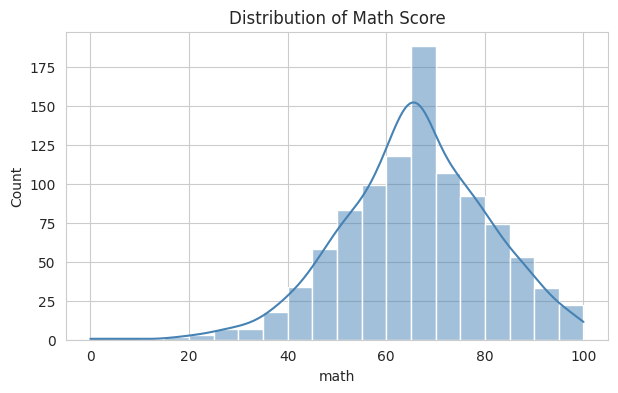

Skewness of math score: -0.284


In [ ]:
# ---------- Histogram ----------
plt.figure(figsize=(7,4))
sns.histplot(df_clean['math'], bins=20, kde=True, color='steelblue')
plt.title('Distribution of Math Score')
plt.show()
print('Skewness of math score:', round(df_clean['math'].skew(), 3))

**Histogram insight:** The bars form an approximate bell shape (roughly normal). Skewness is slightly negative (small tail on the left = a few students with very low marks). Most students score between 55 and 80.

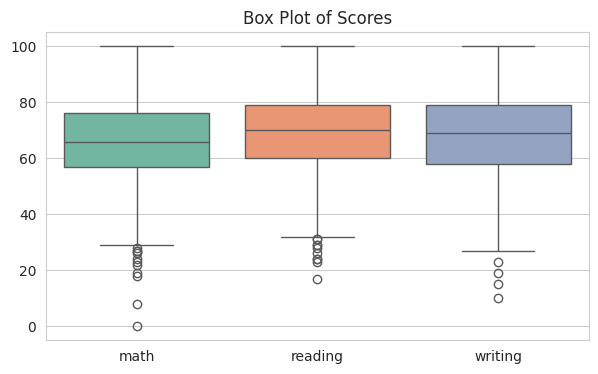

In [ ]:
# ---------- Box plot ----------
plt.figure(figsize=(7,4))
sns.boxplot(data=df_clean[['math','reading','writing']], palette='Set2')
plt.title('Box Plot of Scores')
plt.show()

**Box plot insight:** The line inside each box is the **median**, the box is Q1–Q3 (middle 50% students), and dots below the whiskers are **outliers** (students with unusually low marks). Math has the lowest median and the most outliers.

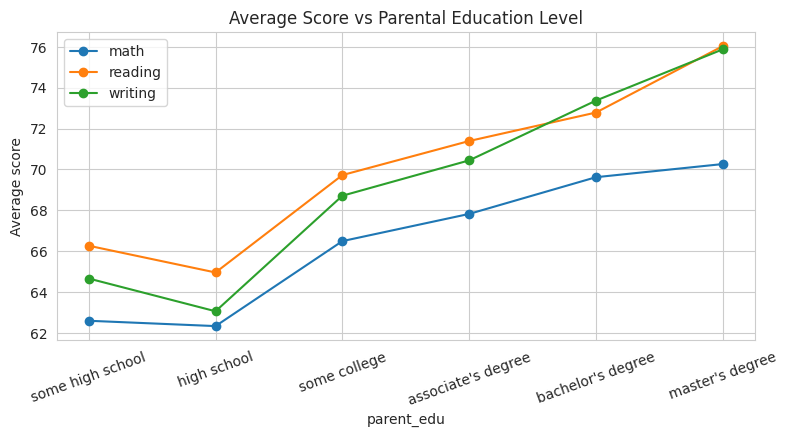

In [ ]:
# ---------- Line plot: trend across an ORDERED variable (parent education level) ----------
order = ['some high school','high school','some college',"associate's degree","bachelor's degree","master's degree"]
trend = df_clean.groupby('parent_edu')[['math','reading','writing']].mean().reindex(order)
trend.plot(kind='line', marker='o', figsize=(9,4))
plt.xticks(range(len(order)), order, rotation=20)
plt.title('Average Score vs Parental Education Level')
plt.ylabel('Average score')
plt.show()

**Line plot insight:** Average scores generally rise as the parents' education level increases, so parental education is positively related to student results.

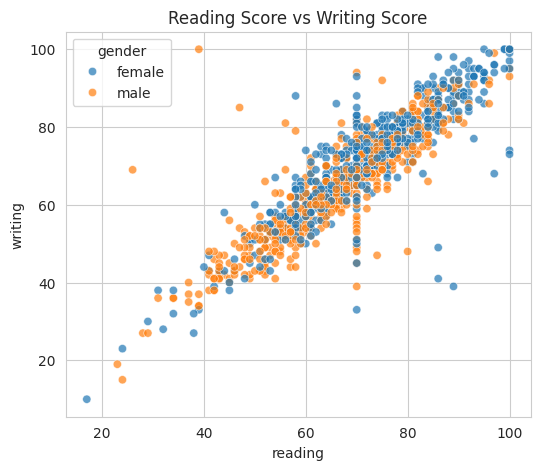

Correlation (reading, writing): 0.883


In [ ]:
# ---------- Scatter plot ----------
plt.figure(figsize=(6,5))
sns.scatterplot(data=df_clean, x='reading', y='writing', hue='gender', alpha=0.7)
plt.title('Reading Score vs Writing Score')
plt.show()
print('Correlation (reading, writing):', round(df_clean['reading'].corr(df_clean['writing']), 3))

**Scatter plot insight:** The points form a tight upward line, i.e. a **strong positive correlation** (≈ 0.95): students who read well also write well. (This means the two features carry similar information – useful for feature extraction later.)

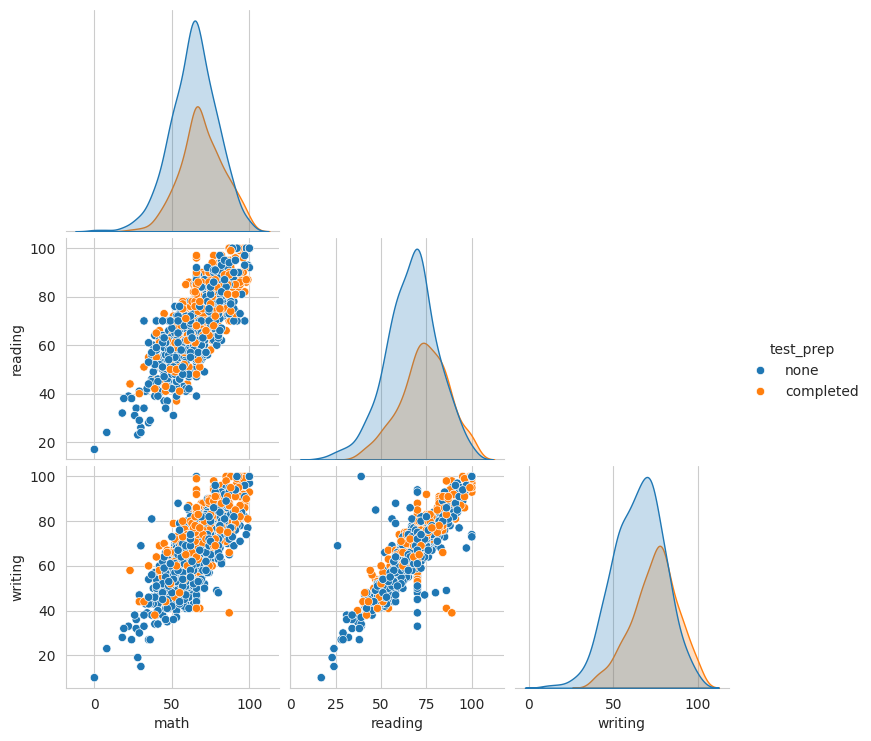

In [ ]:
# ---------- Pair plot ----------
sns.pairplot(df_clean[['math','reading','writing','test_prep']], hue='test_prep', corner=True)
plt.show()

**Pair plot insight:** It shows every pair of scores plus each score's distribution. All three subjects are positively related (reading–writing strongest), and the 'completed' group (orange) is shifted towards higher scores.

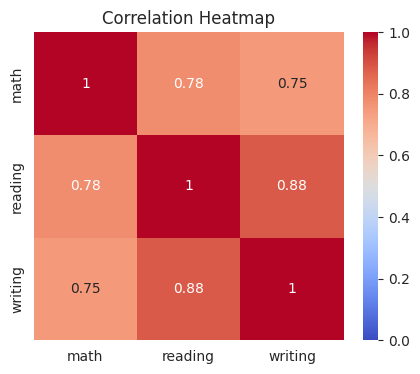

In [ ]:
# ---------- Correlation heatmap (bonus) ----------
plt.figure(figsize=(5,4))
sns.heatmap(df_clean[['math','reading','writing']].corr(), annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

**Heatmap insight:** Numbers close to 1 mean strong relation. Reading and writing are almost perfectly related; math is also strongly related to both.

## 4️⃣ Data Visualization – Categorical Data

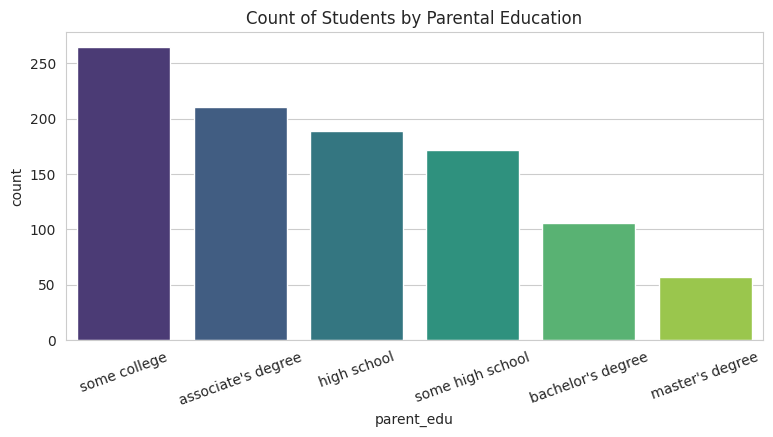

In [ ]:
# ---------- Count plot ----------
plt.figure(figsize=(9,4))
sns.countplot(data=df_clean, x='parent_edu', order=df_clean['parent_edu'].value_counts().index, palette='viridis')
plt.xticks(rotation=20)
plt.title('Count of Students by Parental Education')
plt.show()

**Count plot insight:** It counts students in each category. 'Some college', 'associate's degree' and 'high school' are the most common; 'master's degree' is the least common.

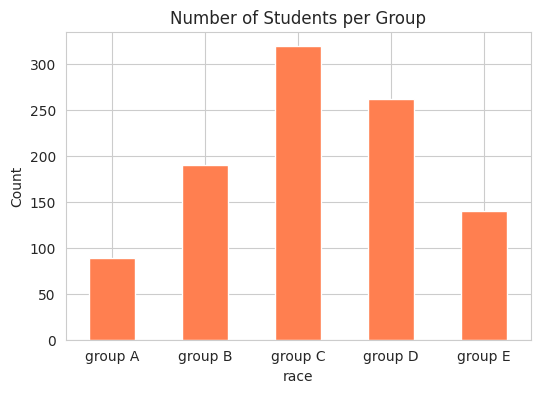

In [ ]:
# ---------- Bar chart (race/ethnicity groups) ----------
df_clean['race'].value_counts().sort_index().plot(kind='bar', figsize=(6,4), color='coral', rot=0)
plt.title('Number of Students per Group')
plt.ylabel('Count')
plt.show()

**Bar chart insight:** Group C and D have the most students; Group A has the fewest. The groups are unbalanced.

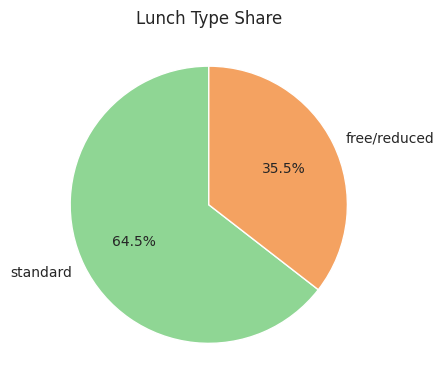

In [ ]:
# ---------- Pie chart ----------
df_clean['lunch'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(4.5,4.5),
                                      colors=['#8fd694','#f4a261'], startangle=90)
plt.ylabel('')
plt.title('Lunch Type Share')
plt.show()

**Pie chart insight:** About two-thirds of students have a *standard* lunch and one-third get *free/reduced* lunch (a rough indicator of family income, linked to SDG 1/SDG 4).

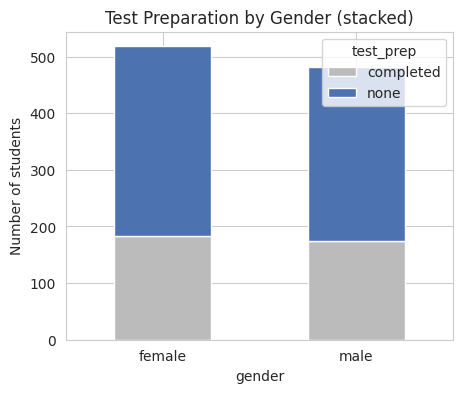

In [ ]:
# ---------- Stacked bar chart ----------
ct = pd.crosstab(df_clean['gender'], df_clean['test_prep'])
ct.plot(kind='bar', stacked=True, figsize=(5,4), rot=0, color=['#bbbbbb','#4c72b0'])
plt.title('Test Preparation by Gender (stacked)')
plt.ylabel('Number of students')
plt.show()

**Stacked bar insight:** Each bar is split into 'completed' and 'none'. For both genders, most students have **not** completed the course (only about one-third have), and the split is similar for males and females.

## 5️⃣ Categorical Encoding
ML models understand only numbers, so we convert text columns to numbers.

In [ ]:
print('BEFORE encoding (categorical columns):')
display(df_clean[cat_cols].head())

BEFORE encoding (categorical columns):


,gender,race,parent_edu,lunch,test_prep
0,female,group B,bachelor's degree,standard,none
1,female,group C,some college,standard,completed
2,female,group B,master's degree,standard,none
3,male,group A,associate's degree,free/reduced,none
4,male,group C,some college,standard,none


In [ ]:
enc = df_clean.copy()

# ---- 1) Label Encoding: gender, test_prep (2 categories) ----
le = LabelEncoder()
enc['gender_label']    = le.fit_transform(enc['gender'])       # female=0, male=1
enc['test_prep_label'] = LabelEncoder().fit_transform(enc['test_prep'])   # completed=0, none=1

# ---- 2) Ordinal Encoding: parent_edu (has a natural ORDER) ----
edu_order = [['some high school','high school','some college',"associate's degree","bachelor's degree","master's degree"]]
enc['parent_edu_ordinal'] = OrdinalEncoder(categories=edu_order).fit_transform(enc[['parent_edu']]).astype(int)

# ---- 3) One-Hot Encoding: lunch (no order) ----
onehot = pd.get_dummies(enc['lunch'], prefix='lunch', dtype=int)
enc = pd.concat([enc, onehot], axis=1)

# ---- 4) Binary Encoding: race (5 groups -> only 3 binary columns) ----
binary = ce.BinaryEncoder(cols=['race']).fit_transform(enc[['race']])
enc = pd.concat([enc, binary], axis=1)

print('AFTER encoding (new columns added):')
display(enc[['gender','gender_label','test_prep','test_prep_label','parent_edu','parent_edu_ordinal']].head())
display(enc[['lunch'] + list(onehot.columns)].head())
display(pd.concat([df_clean[['race']], binary], axis=1).head())

AFTER encoding (new columns added):


,gender,gender_label,test_prep,test_prep_label,parent_edu,parent_edu_ordinal
0,female,0,none,1,bachelor's degree,4
1,female,0,completed,0,some college,2
2,female,0,none,1,master's degree,5
3,male,1,none,1,associate's degree,3
4,male,1,none,1,some college,2


,lunch,lunch_free/reduced,lunch_standard
0,standard,0,1
1,standard,0,1
2,standard,0,1
3,free/reduced,1,0
4,standard,0,1


,race,race_0,race_1,race_2
0,group B,0,0,1
1,group C,0,1,0
2,group B,0,0,1
3,group A,0,1,1
4,group C,0,1,0


### When to use which encoding?
| Technique | Use when | Our example |
|---|---|---|
| **Label Encoding** | Only 2 categories (or the target label); no meaningful order | `gender`, `test_prep` |
| **Ordinal Encoding** | Categories have a natural **order/ranking** | `parent_edu` (school < college < degree) |
| **One-Hot Encoding** | Few categories, **no order**; avoids fake ranking | `lunch` (and `race`, since only 5 groups) |
| **Binary Encoding** | **Many categories** (high cardinality); fewer columns than one-hot | `race` (5 groups → 3 columns instead of 5) |

## 6️⃣ Feature Scaling
Scores are all out of 100 here, but scaling is still shown so the techniques are clear. Scaling puts features on a similar range so that no feature dominates (important for KNN, SVM, gradient descent, etc.).

In [ ]:
X = df_clean[['math','reading','writing']]
scaled = pd.DataFrame()

std = pd.DataFrame(StandardScaler().fit_transform(X),  columns=X.columns)
mm  = pd.DataFrame(MinMaxScaler().fit_transform(X),    columns=X.columns)
rb  = pd.DataFrame(RobustScaler().fit_transform(X),    columns=X.columns)
nrm = pd.DataFrame(Normalizer(norm='l2').fit_transform(X), columns=X.columns)

print('ORIGINAL values');            display(X.head())
print('1) StandardScaler  -> (x - mean) / std');         display(std.head())
print('2) MinMaxScaler    -> (x - min) / (max - min)');  display(mm.head())
print('3) RobustScaler    -> (x - median) / IQR');       display(rb.head())
print('4) Normalizer (L2) -> each ROW scaled to length 1'); display(nrm.head())

ORIGINAL values


,math,reading,writing
0,72.0,72.0,74.0
1,69.0,90.0,88.0
2,90.0,95.0,93.0
3,47.0,57.0,44.0
4,76.0,78.0,75.0


1) StandardScaler  -> (x - mean) / std


,math,reading,writing
0,0.415373,0.191979,0.384604
1,0.212457,1.453614,1.314721
2,1.632871,1.804069,1.646906
3,-1.275596,-0.859384,-1.608506
4,0.685928,0.612524,0.451041


2) MinMaxScaler    -> (x - min) / (max - min)


,math,reading,writing
0,0.72,0.662651,0.711111
1,0.69,0.879518,0.866667
2,0.90,0.939759,0.922222
3,0.47,0.481928,0.377778
4,0.76,0.734940,0.722222


3) RobustScaler    -> (x - median) / IQR


,math,reading,writing
0,0.323213,0.105263,0.238095
1,0.165319,1.052632,0.904762
2,1.270582,1.315789,1.142857
3,-0.992576,-0.684211,-1.190476
4,0.533740,0.421053,0.285714


4) Normalizer (L2) -> each ROW scaled to length 1


,math,reading,writing
0,0.572005,0.572005,0.587894
1,0.480687,0.626984,0.613051
2,0.560598,0.591742,0.579285
3,0.546586,0.662880,0.511697
4,0.574752,0.589877,0.567190


,Original,Standard,MinMax,Robust
mean,65.859,-0.000,0.659,-0.000
std,14.792,1.001,0.148,0.779
min,0.000,-4.455,0.000,-3.466
max,100.000,2.309,1.000,1.797


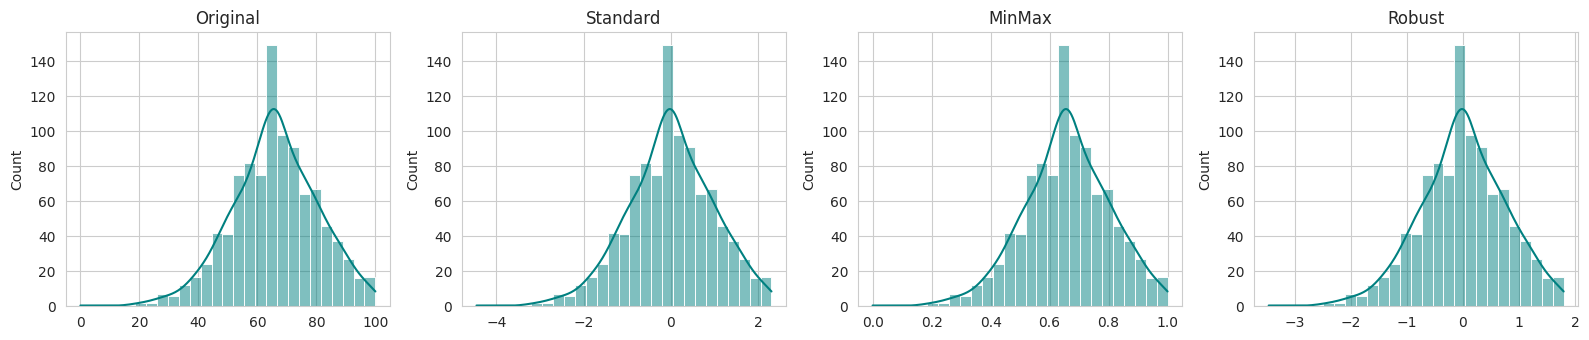

In [ ]:
# ---------- Summary comparison for 'math' ----------
summary = pd.DataFrame({
    'Original':  X['math'].describe(),
    'Standard':  std['math'].describe(),
    'MinMax':    mm['math'].describe(),
    'Robust':    rb['math'].describe(),
}).loc[['mean','std','min','max']].round(3)
display(summary)

# ---------- Visual comparison (shape stays the same, only the scale changes) ----------
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, (name, data) in zip(ax, [('Original', X['math']), ('Standard', std['math']),
                                ('MinMax', mm['math']), ('Robust', rb['math'])]):
    sns.histplot(data, kde=True, ax=a, color='teal'); a.set_title(name); a.set_xlabel('')
plt.tight_layout(); plt.show()

### Difference between scaling techniques
| Technique | Formula | Result range | Best when |
|---|---|---|---|
| **StandardScaler** | (x − mean) / std | Mean = 0, Std = 1 (no fixed range) | Data is roughly normal; most ML models (Logistic Reg., SVM, PCA) |
| **MinMaxScaler** | (x − min) / (max − min) | 0 to 1 | Need a fixed range; neural networks, KNN; no big outliers |
| **RobustScaler** | (x − median) / IQR | Centred at 0 | Data has **outliers** (uses median & IQR, so outliers don't affect it) |
| **Normalizer** | x / ‖x‖ (per row) | Each row has length 1 | Works **row-wise** (not column-wise); text data, cosine similarity |

**Observation:** The histogram shape remains the same in all plots – scaling changes only the *range/units*, not the distribution.

## 7️⃣ Feature Engineering
We create new, meaningful features from existing columns.

In [ ]:
fe = df_clean.copy()

# ================= A) FEATURE CREATION =================
fe['total_score']   = fe['math'] + fe['reading'] + fe['writing']        # overall marks out of 300
fe['average_score'] = (fe['total_score'] / 3).round(2)                  # overall average
fe['grade_level']   = pd.cut(fe['average_score'], bins=[0, 40, 60, 80, 100],
                             labels=['Low', 'Average', 'Good', 'Excellent'], include_lowest=True)   # binning
fe['result'] = np.where(fe['average_score'] >= 40, 'Pass', 'Fail')     # pass/fail flag

display(fe[['math','reading','writing','total_score','average_score','grade_level','result']].head())
print(fe['grade_level'].value_counts())

,math,reading,writing,total_score,average_score,grade_level,result
0,72.0,72.0,74.0,218.0,72.67,Good,Pass
1,69.0,90.0,88.0,247.0,82.33,Excellent,Pass
2,90.0,95.0,93.0,278.0,92.67,Excellent,Pass
3,47.0,57.0,44.0,148.0,49.33,Average,Pass
4,76.0,78.0,75.0,229.0,76.33,Good,Pass


grade_level
Good         542
Average      251
Excellent    179
Low           28
Name: count, dtype: int64


**New features and why**
- `total_score`, `average_score`: one number to represent the overall performance instead of three separate scores.
- `grade_level`: converts a continuous average into 4 easy groups (binning) – easier to analyse / classify.
- `result`: Pass/Fail target – useful for a classification model.

Skewness BEFORE: -0.284 | AFTER: -0.003


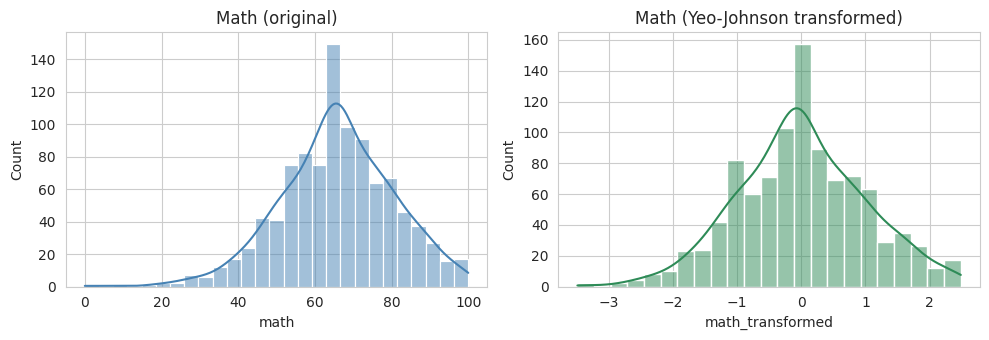

In [ ]:
# ================= B) FEATURE TRANSFORMATION =================
# Math score is slightly skewed. Yeo-Johnson transformation makes the data more bell-shaped (normal).
pt = PowerTransformer(method='yeo-johnson')
fe['math_transformed'] = pt.fit_transform(fe[['math']])

print('Skewness BEFORE:', round(fe['math'].skew(), 3), '| AFTER:', round(fe['math_transformed'].skew(), 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(fe['math'], kde=True, ax=ax[0], color='steelblue');            ax[0].set_title('Math (original)')
sns.histplot(fe['math_transformed'], kde=True, ax=ax[1], color='seagreen'); ax[1].set_title('Math (Yeo-Johnson transformed)')
plt.tight_layout(); plt.show()

**Why:** Many ML models work best when features are close to normally distributed. The transformation reduces skewness (closer to 0) and makes the curve more symmetric.

In [ ]:
# ================= C) FEATURE EXTRACTION (PCA) =================
# Math, reading, writing are highly correlated -> compress the 3 scores into 1 new feature using PCA
scores_scaled = StandardScaler().fit_transform(fe[['math','reading','writing']])
pca = PCA(n_components=1)
fe['ability_index'] = pca.fit_transform(scores_scaled)

print('Variance explained by the 1 new component: {:.1f}%'.format(pca.explained_variance_ratio_[0] * 100))
display(fe[['math','reading','writing','ability_index']].head())

Variance explained by the 1 new component: 86.9%


,math,reading,writing,ability_index
0,72.0,72.0,74.0,0.569390
1,69.0,90.0,88.0,1.743976
2,90.0,95.0,93.0,2.936620
3,47.0,57.0,44.0,-2.157337
4,76.0,78.0,75.0,1.007267


**Why:** PCA extracts one new feature (`ability_index`) that keeps most of the information (~90%) of the three correlated scores. This reduces dimensions and removes repeated information.

Q1=57.0, Q3=76.0, IQR=19.0  ->  valid range = [28.5, 104.5]
Number of outliers in math: 11


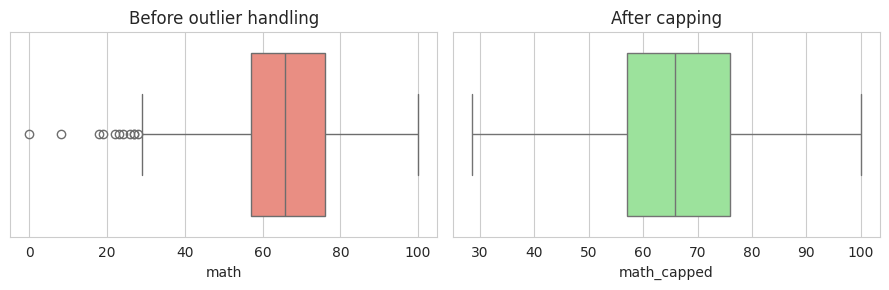

In [ ]:
# ================= D) HANDLING OUTLIERS (IQR method) =================
Q1, Q3 = fe['math'].quantile(0.25), fe['math'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f'Q1={Q1}, Q3={Q3}, IQR={IQR}  ->  valid range = [{lower:.1f}, {upper:.1f}]')
print('Number of outliers in math:', ((fe['math'] < lower) | (fe['math'] > upper)).sum())

# Capping (winsorizing): replace extreme values with the limit instead of deleting students
fe['math_capped'] = fe['math'].clip(lower, upper)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
sns.boxplot(x=fe['math'], ax=ax[0], color='salmon');        ax[0].set_title('Before outlier handling')
sns.boxplot(x=fe['math_capped'], ax=ax[1], color='lightgreen'); ax[1].set_title('After capping')
plt.tight_layout(); plt.show()

**Why capping:** Outliers (very low scores) can distort the mean and mislead the model. Instead of deleting rows (we would lose data), we **cap** them to the IQR limits. The box plot after capping shows no dots.

## 8️⃣ Final Preprocessed Dataset
Combining everything: cleaned data + encoded categorical columns + scaled numerical columns + new features.

In [ ]:
final = pd.DataFrame()

# --- Encoded categorical features ---
final['gender']     = LabelEncoder().fit_transform(fe['gender'])                       # label
final['test_prep']  = LabelEncoder().fit_transform(fe['test_prep'])                    # label
final['parent_edu'] = OrdinalEncoder(categories=edu_order).fit_transform(fe[['parent_edu']]).ravel().astype(int)  # ordinal
final['grade_level'] = OrdinalEncoder(categories=[['Low','Average','Good','Excellent']]).fit_transform(fe[['grade_level']]).ravel().astype(int)
final = pd.concat([final,
                   pd.get_dummies(fe['race'],  prefix='race',  dtype=int),             # one-hot
                   pd.get_dummies(fe['lunch'], prefix='lunch', dtype=int)], axis=1)

# --- Scaled numerical features (StandardScaler) ---
num_final = ['math_capped', 'reading', 'writing', 'total_score', 'average_score', 'ability_index']
final[num_final] = StandardScaler().fit_transform(fe[num_final])

# --- Target column ---
final['result'] = (fe['result'] == 'Pass').astype(int)       # Pass=1, Fail=0

print('Final dataset shape:', final.shape)
print('Missing values left:', final.isnull().sum().sum())
display(final.head())
final.info()

Final dataset shape: (1000, 18)
Missing values left: 0


,gender,test_prep,parent_edu,grade_level,race_group A,race_group B,race_group C,race_group D,race_group E,lunch_free/reduced,lunch_standard,math_capped,reading,writing,total_score,average_score,ability_index,result
0,0,1,4,2,0,1,0,0,0,0,1,0.417263,0.191979,0.384604,0.356855,0.357098,0.352547,1
1,0,0,2,3,0,0,1,0,0,0,1,0.210340,1.453614,1.314721,1.062341,1.062097,1.079812,1
2,0,1,5,3,0,1,0,0,0,0,1,1.658798,1.804069,1.646906,1.816481,1.816724,1.818257,1
3,1,1,3,1,1,0,0,0,0,1,0,-1.307091,-0.859384,-1.608506,-1.346041,-1.346287,-1.335751,1
4,1,1,2,2,0,0,1,0,0,0,1,0.693159,0.612524,0.451041,0.624453,0.624209,0.623666,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              1000 non-null   int64  
 1   test_prep           1000 non-null   int64  
 2   parent_edu          1000 non-null   int64  
 3   grade_level         1000 non-null   int64  
 4   race_group A        1000 non-null   int64  
 5   race_group B        1000 non-null   int64  
 6   race_group C        1000 non-null   int64  
 7   race_group D        1000 non-null   int64  
 8   race_group E        1000 non-null   int64  
 9   lunch_free/reduced  1000 non-null   int64  
 10  lunch_standard      1000 non-null   int64  
 11  math_capped         1000 non-null   float64
 12  reading             1000 non-null   float64
 13  writing             1000 non-null   float64
 14  total_score         1000 non-null   float64
 15  average_score       1000 non-null   float64
 16  ability

In [ ]:
# Save the final dataset (and download it if running in Colab)
final.to_csv('final_preprocessed_dataset.csv', index=False)
try:
    from google.colab import files
    files.download('final_preprocessed_dataset.csv')
except Exception:
    print('Saved as final_preprocessed_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ✅ Conclusion
- Loaded the **Students Performance** dataset (SDG 4 – Quality Education) and explored it using `head()`, `tail()`, `shape`, `info()`, `describe()`.
- Handled missing values using **mean, median, random sample and mode**.
- Visualized numerical (bar, histogram, box, line, scatter, pair plot) and categorical (count, bar, pie, stacked bar) data with insights.
- Encoded categories using **Label, Ordinal, One-Hot and Binary encoding**.
- Scaled features using **StandardScaler, MinMaxScaler, RobustScaler and Normalizer**.
- Engineered new features: **total/average score, grade level (creation), Yeo-Johnson (transformation), PCA ability index (extraction), IQR capping (outliers)**.
- Final output is a clean, numeric, scaled dataset ready for a machine-learning model.

**SDG link:** The insights (test-prep, parental education and lunch type affecting scores) can help schools and governments design support programs for better learning outcomes.